# LFW AuraFace baseline

Inspect the saved recognition-only baseline and compare future runs. No Firebase credentials are needed. This notebook reads saved results; it does not start a lengthy benchmark automatically. See `docs/lfw_benchmark.md` for the full procedure.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
RUN = ROOT / 'data/benchmarks/lfw_auraface_baseline'
assert (RUN / 'run.json').exists(), 'Run src/scripts/benchmark_lfw.py first'
run = json.loads((RUN / 'run.json').read_text(encoding='utf-8'))
display(Markdown((RUN / 'report.md').read_text(encoding='utf-8')))


# LFW AuraFace baseline

Recognition only, 6,000 pairs; CPU, one image at a time, no flip augmentation.

| Metric | Result |
|---|---:|
| 10-fold accuracy | 99.27% |
| Always predict different person (reference) | 50.00% |
| Fold accuracy standard deviation | 0.396 percentage points |
| ROC AUC | 0.998822 |
| False accepts / rejects | 11 / 33 |
| TAR at training FAR target 1% | 99.27% |
| Actual held-out FAR at that operating point | 1.00% |
| Median / p95 image latency | 50.6 / 67.8 ms |
| Image failures | 0 |

At the separately fixed cosine threshold 0.550, accuracy is 82.83%, false accept rate 0.00%, and false reject rate 34.33%. Zero observed false accepts is not proof of zero population risk. Do not deploy a threshold selected only from these LFW results.

Thresholds are selected on nine folds and evaluated on the remaining fold. Fold standard deviation is not a confidence interval. ROC AUC is descriptive over all pairs. The 1% training FAR target does not guarantee 1% held-out FAR. Fixed-threshold results in run.json use a separately supplied threshold; they are not the CV score.

## Limits

- Prepared crops; no detector/alignment benchmark
- Official pair identities/order not independently verified
- Pretraining overlap unknown
- Single pass; no horizontal flip augmentation
- Folds may share identities; not identity-disjoint evaluation

Compare future runs on this same dataset hash and protocol. Compare latency only with the same hardware, thread count and preprocessing. Do not claim event-photo or Google Cloud performance from this result.


## Score distributions and ROC

ROC is descriptive across all pairs. Cross-validated accuracy uses a training-selected threshold for each held-out fold.


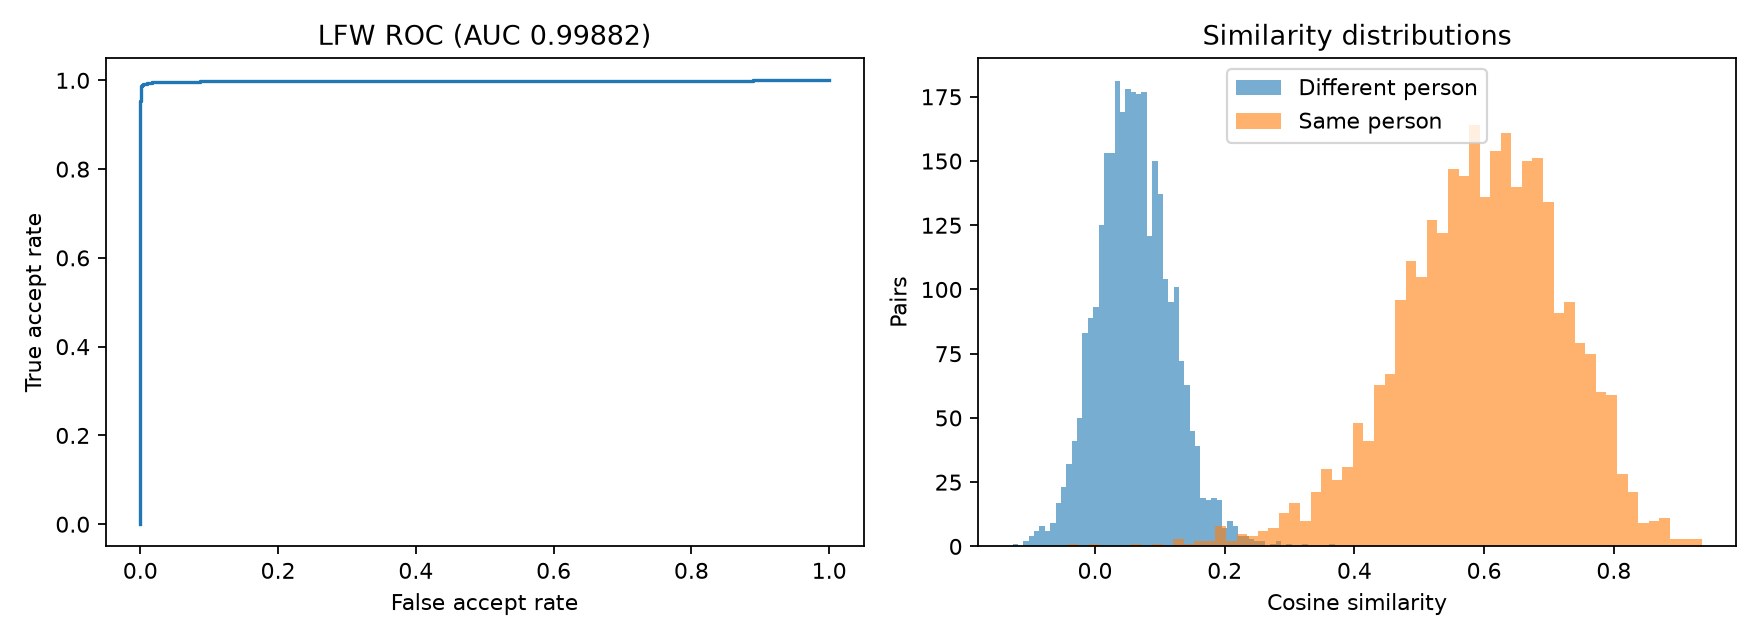

,fold,threshold,threshold_at_training_far_1pct,tp,tn,fp,fn,accuracy,true_accept_rate,false_accept_rate,false_reject_rate,precision,f1,low_far_test_tar,low_far_test_far
0,1,0.255,0.212,296,299,1,4,0.991667,0.986667,0.003333,0.013333,0.996633,0.991625,0.990000,0.010000
1,2,0.245,0.212,296,299,1,4,0.991667,0.986667,0.003333,0.013333,0.996633,0.991625,0.990000,0.010000
2,3,0.255,0.212,298,299,1,2,0.995000,0.993333,0.003333,0.006667,0.996656,0.994992,1.000000,0.010000
3,4,0.261,0.212,293,300,0,7,0.988333,0.976667,0.000000,0.023333,1.000000,0.988196,0.983333,0.006667
4,5,0.255,0.212,294,300,0,6,0.990000,0.980000,0.000000,0.020000,1.000000,0.989899,0.983333,0.006667
5,6,0.255,0.212,299,299,1,1,0.996667,0.996667,0.003333,0.003333,0.996667,0.996667,1.000000,0.010000
6,7,0.253,0.212,293,299,1,7,0.986667,0.976667,0.003333,0.023333,0.996599,0.986532,0.986667,0.006667
7,8,0.255,0.212,300,299,1,0,0.998333,1.000000,0.003333,0.000000,0.996678,0.998336,1.000000,0.010000
8,9,0.241,0.213,300,299,1,0,0.998333,1.000000,0.003333,0.000000,0.996678,0.998336,1.000000,0.003333
9,10,0.249,0.207,298,296,4,2,0.990000,0.993333,0.013333,0.006667,0.986755,0.990033,0.993333,0.026667


In [2]:
display(Image(filename=str(RUN / 'metrics.png')))
folds = pd.read_csv(RUN / 'folds.csv')
display(folds)


## Inspect mistakes

Only pair indices and scores are displayed here. There is no gallery identification or group-photo detection in this evaluation.


In [3]:
pairs = pd.read_csv(RUN / 'pairs.csv')
display(pairs.loc[~pairs['correct']].sort_values('cosine'))
print('Pair count:', len(pairs))
print('Dataset SHA-256:', run['dataset_sha256'])
print('Model SHA-256:', run['model_sha256'])
print('Inference settings:', run['inference'])


,pair_index,fold,same_person,cosine,threshold,predicted_same,correct
2551,2551,5,True,-0.042417,0.255,False,False
2550,2550,5,True,-0.006122,0.255,False,False
2498,2498,5,True,0.055498,0.255,False,False
1851,1851,4,True,0.091552,0.261,False,False
3641,3641,7,True,0.125672,0.253,False,False
1853,1853,4,True,0.126390,0.261,False,False
2009,2009,4,True,0.130208,0.261,False,False
629,629,2,True,0.138387,0.245,False,False
1861,1861,4,True,0.163993,0.261,False,False
3872,3872,7,True,0.167272,0.253,False,False


Pair count: 6000
Dataset SHA-256: 9b711dca71a47fc9f295a28514abe8cc4e457632a8d634264691398c99569593
Model SHA-256: a7933ea5330113b01c9b60351d8f4c33003f145d8470ac5f0e52ee2effe25c60
Inference settings: {'normalization': {'mean': 127.5, 'std': 127.5}, 'rgb': True, 'horizontal_flip': False, 'detector_used': False, 'threads': 4, 'batch_size': 1, 'warmup_runs': 3, 'latency_scope': 'image decode + preprocessing + ONNX inference + normalization', 'latency_median_ms': 50.601250026375055, 'latency_p95_ms': 67.82174478285013, 'images_per_second': 17.976004847676222, 'failures': []}


## Compare a future run

Change `CANDIDATE` to the folder from a later benchmark. Deltas for rates are fractions; 0.01 is one percentage point. Same dataset, protocol, and preprocessing are required.


In [4]:
import sys
sys.path.insert(0, str(ROOT / 'src/scripts'))
from compare_lfw import compare
CANDIDATE = None  # e.g. ROOT / 'data/benchmarks/my_run'
if CANDIDATE is not None:
    candidate = json.loads((CANDIDATE / 'run.json').read_text(encoding='utf-8'))
    rows, timing_matches = compare(run, candidate)
    display(pd.DataFrame(rows))
    print('Recorded timing settings match:', timing_matches)


## Reproduce

Run in PowerShell from the repository root, using a new output folder:

```powershell
uv pip install --python .venv/Scripts/python.exe -r requirements-benchmark.txt
& .venv/Scripts/python.exe src/scripts/benchmark_lfw.py --output data/benchmarks/my_run
```

Do not interpret LFW scores as event-photo, redaction, or deployed Google Cloud performance. The local derivative's official pair identities/order and pretrained-model training overlap have not been independently verified.


## Threshold tuning

Run from the repository root in PowerShell:

```powershell
& .venv/Scripts/python.exe src/scripts/tune_lfw_threshold.py
```

The default targets at most 0.5% false acceptance on development folds. Actual test FAR can differ. This is a retrospective experiment; the app threshold remains unchanged.


# LFW threshold tuning

Selected objective: `far`; development FAR budget: 0.50%.

| Policy | Accuracy | Genuine acceptance | False acceptance | False rejects | False accepts |
|---|---:|---:|---:|---:|---:|
| Fixed 0.550 | 82.83% | 65.67% | 0.00% | 1030 | 0 |
| CV maximize accuracy | 99.27% | 98.90% | 0.37% | 33 | 11 |
| CV maximize genuine acceptance under FAR budget | 99.28% | 99.07% | 0.50% | 28 | 15 |

Single development candidate: **0.234**. Fit using all pairs; validate it on new event data before deployment.

CV rows select thresholds on nine folds and score the remaining fold; they use different thresholds per fold. The single all-data candidate and sweep are development results, not held-out estimates. This changes the decision rule, not model weights; AUC and inference speed are unchanged.

Retrospective analysis of already inspected LFW results; not a fresh test set
Training FAR budget does not guarantee held-out FAR
Local derivative pair identities/order not independently authenticated
Pair verification does not evaluate gallery ranking or runner-up margin

The app's default remains unchanged. `candidate.json` records the candidate; no gallery margin is tuned by pair data.


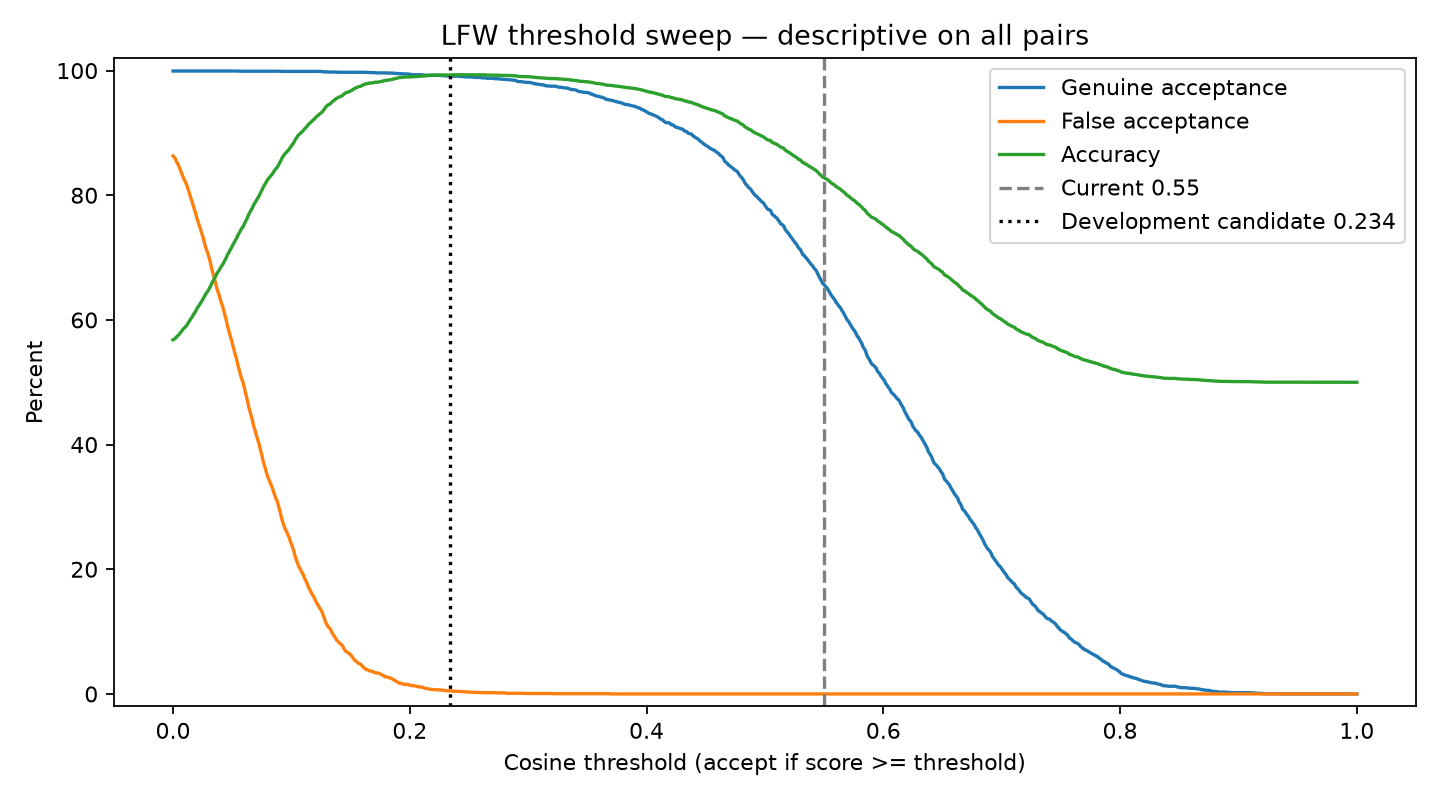

In [5]:
TUNING = ROOT / 'reports/lfw_threshold_tuning'
display(Markdown((TUNING / 'report.md').read_text(encoding='utf-8')))
display(Image(filename=str(TUNING / 'threshold_tradeoff.png')))


## Benchmark and hyperparameter comparison charts

Compare the fixed original threshold, accuracy tuning, and FAR-budget tuning. The model weights are unchanged. The original result is fixed; tuned policies use retrospective 10-fold cross-validation. Recreate the charts with:

```powershell
& .venv/Scripts/python.exe src/scripts/visualize_lfw_benchmarks.py
```


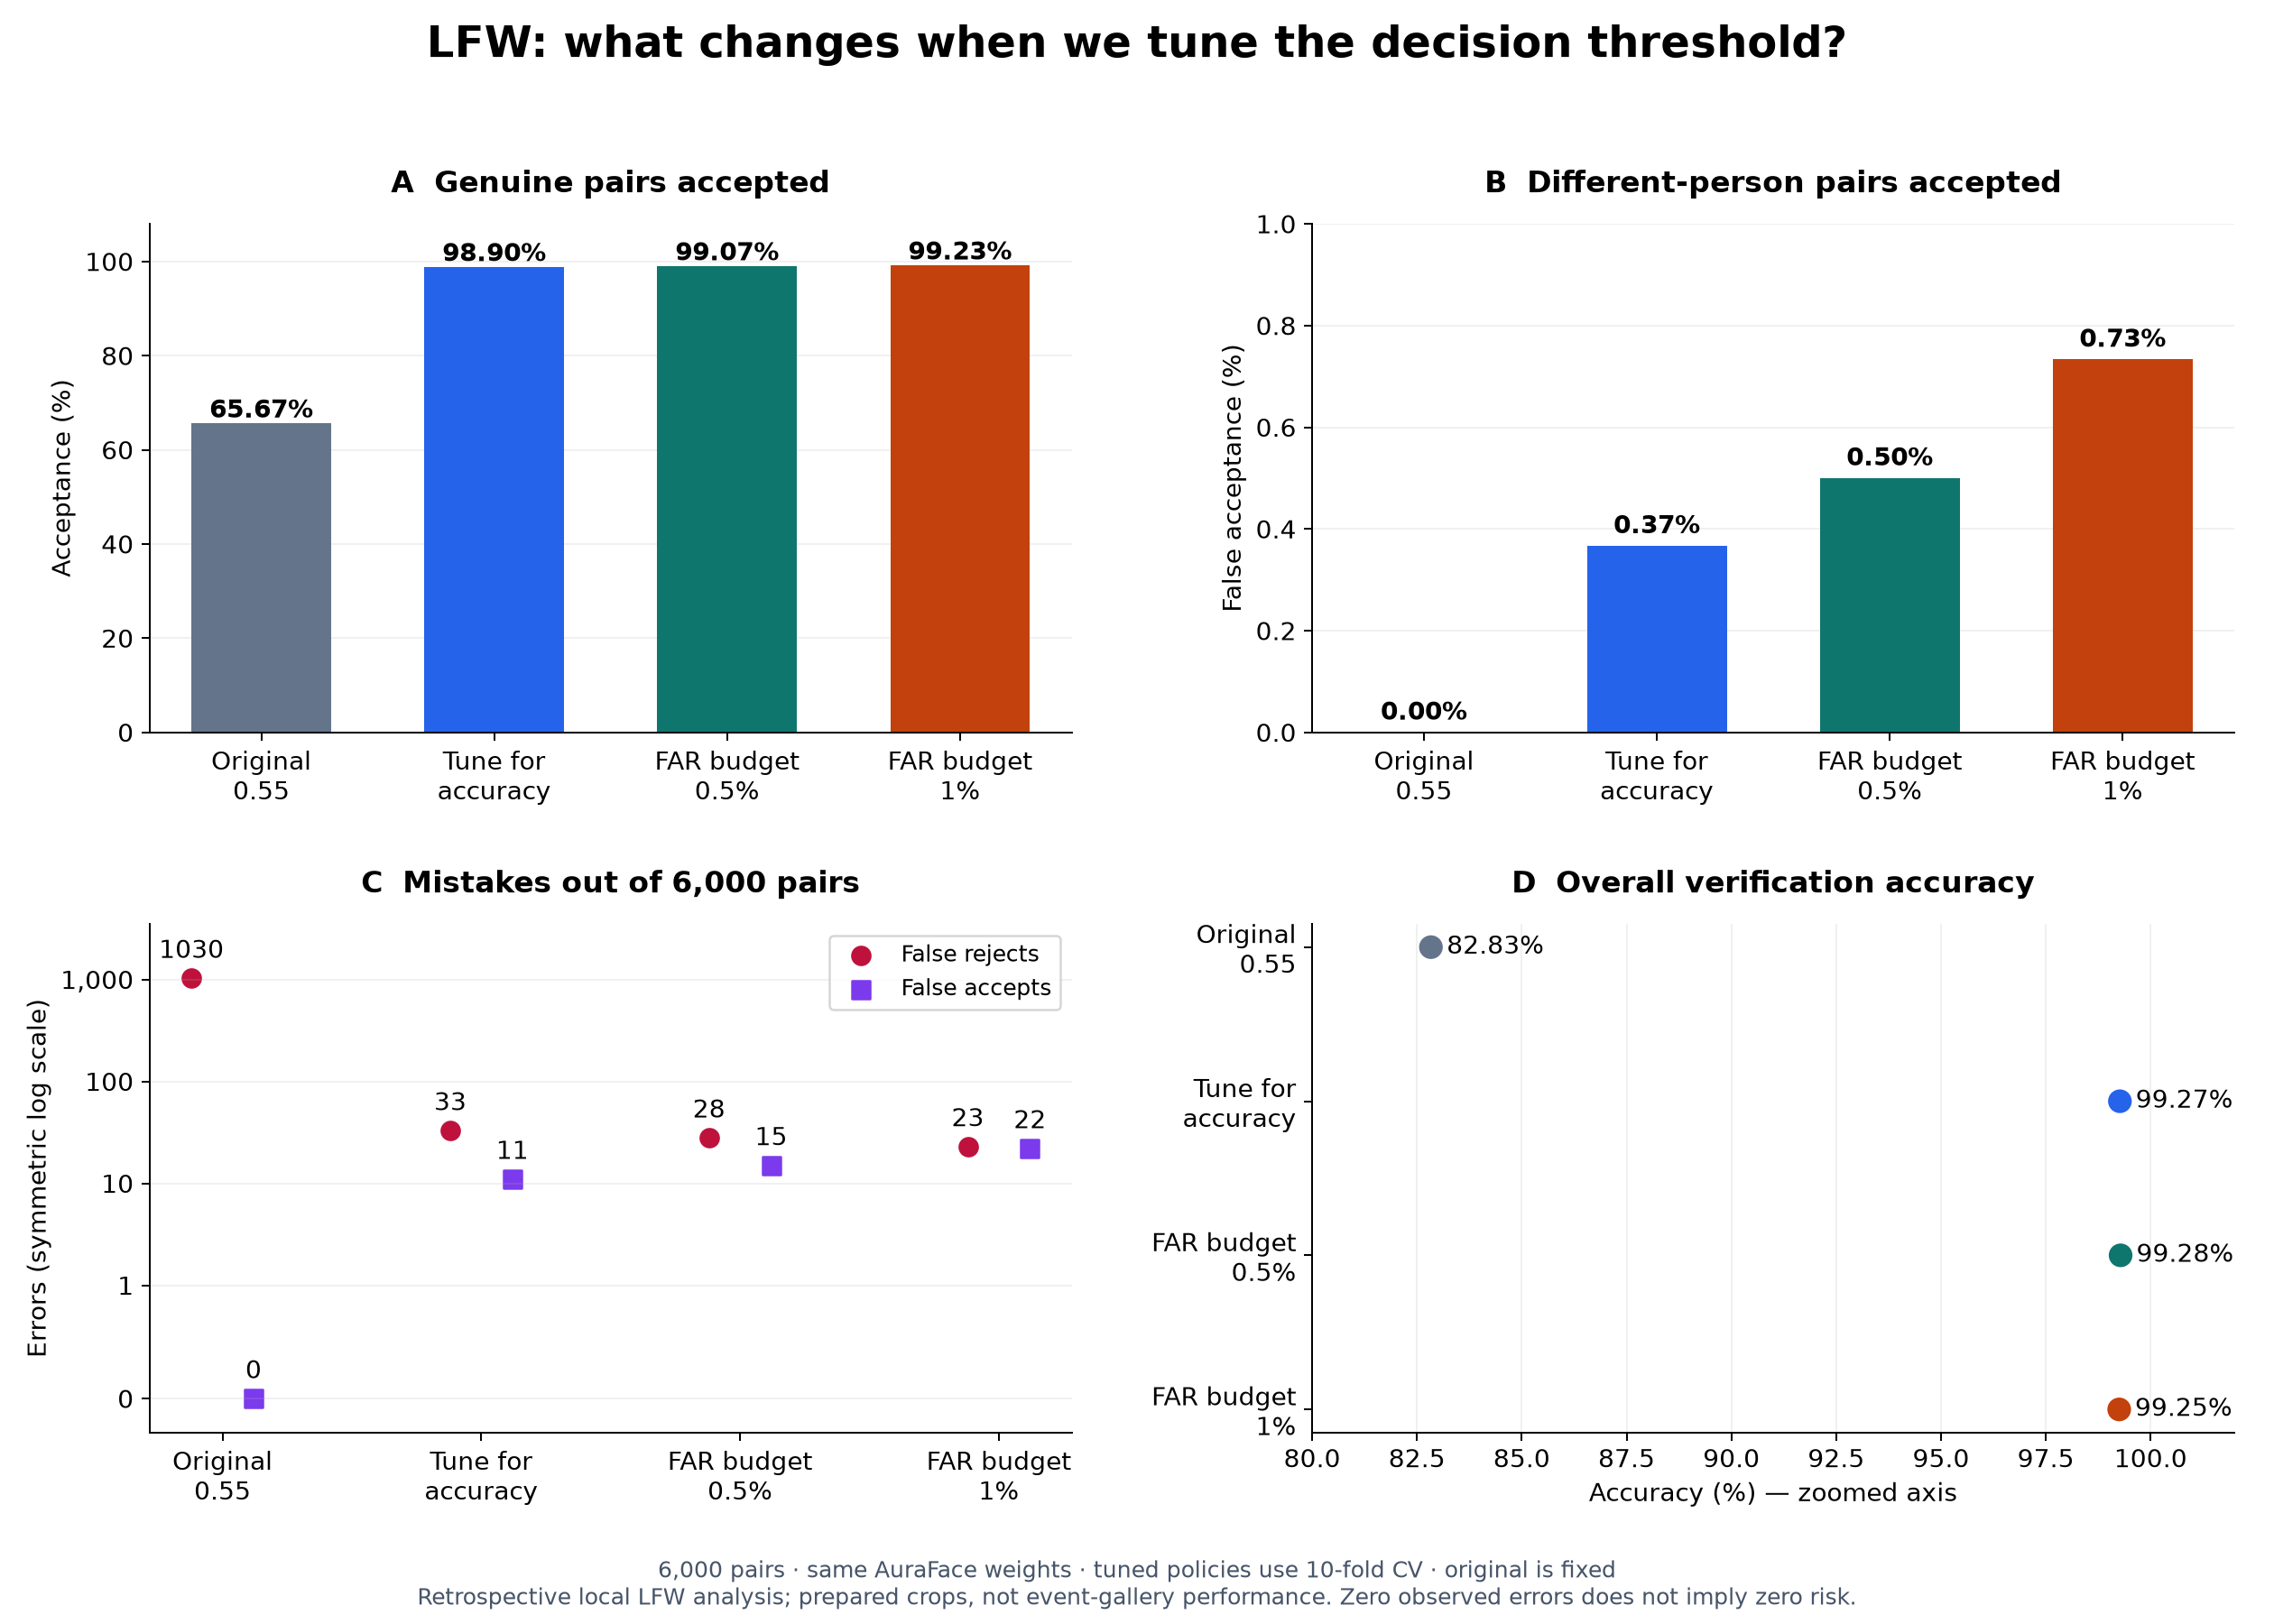

In [6]:
display(Image(filename=str(ROOT / 'reports/lfw_visualizations/01_policy_comparison.png')))


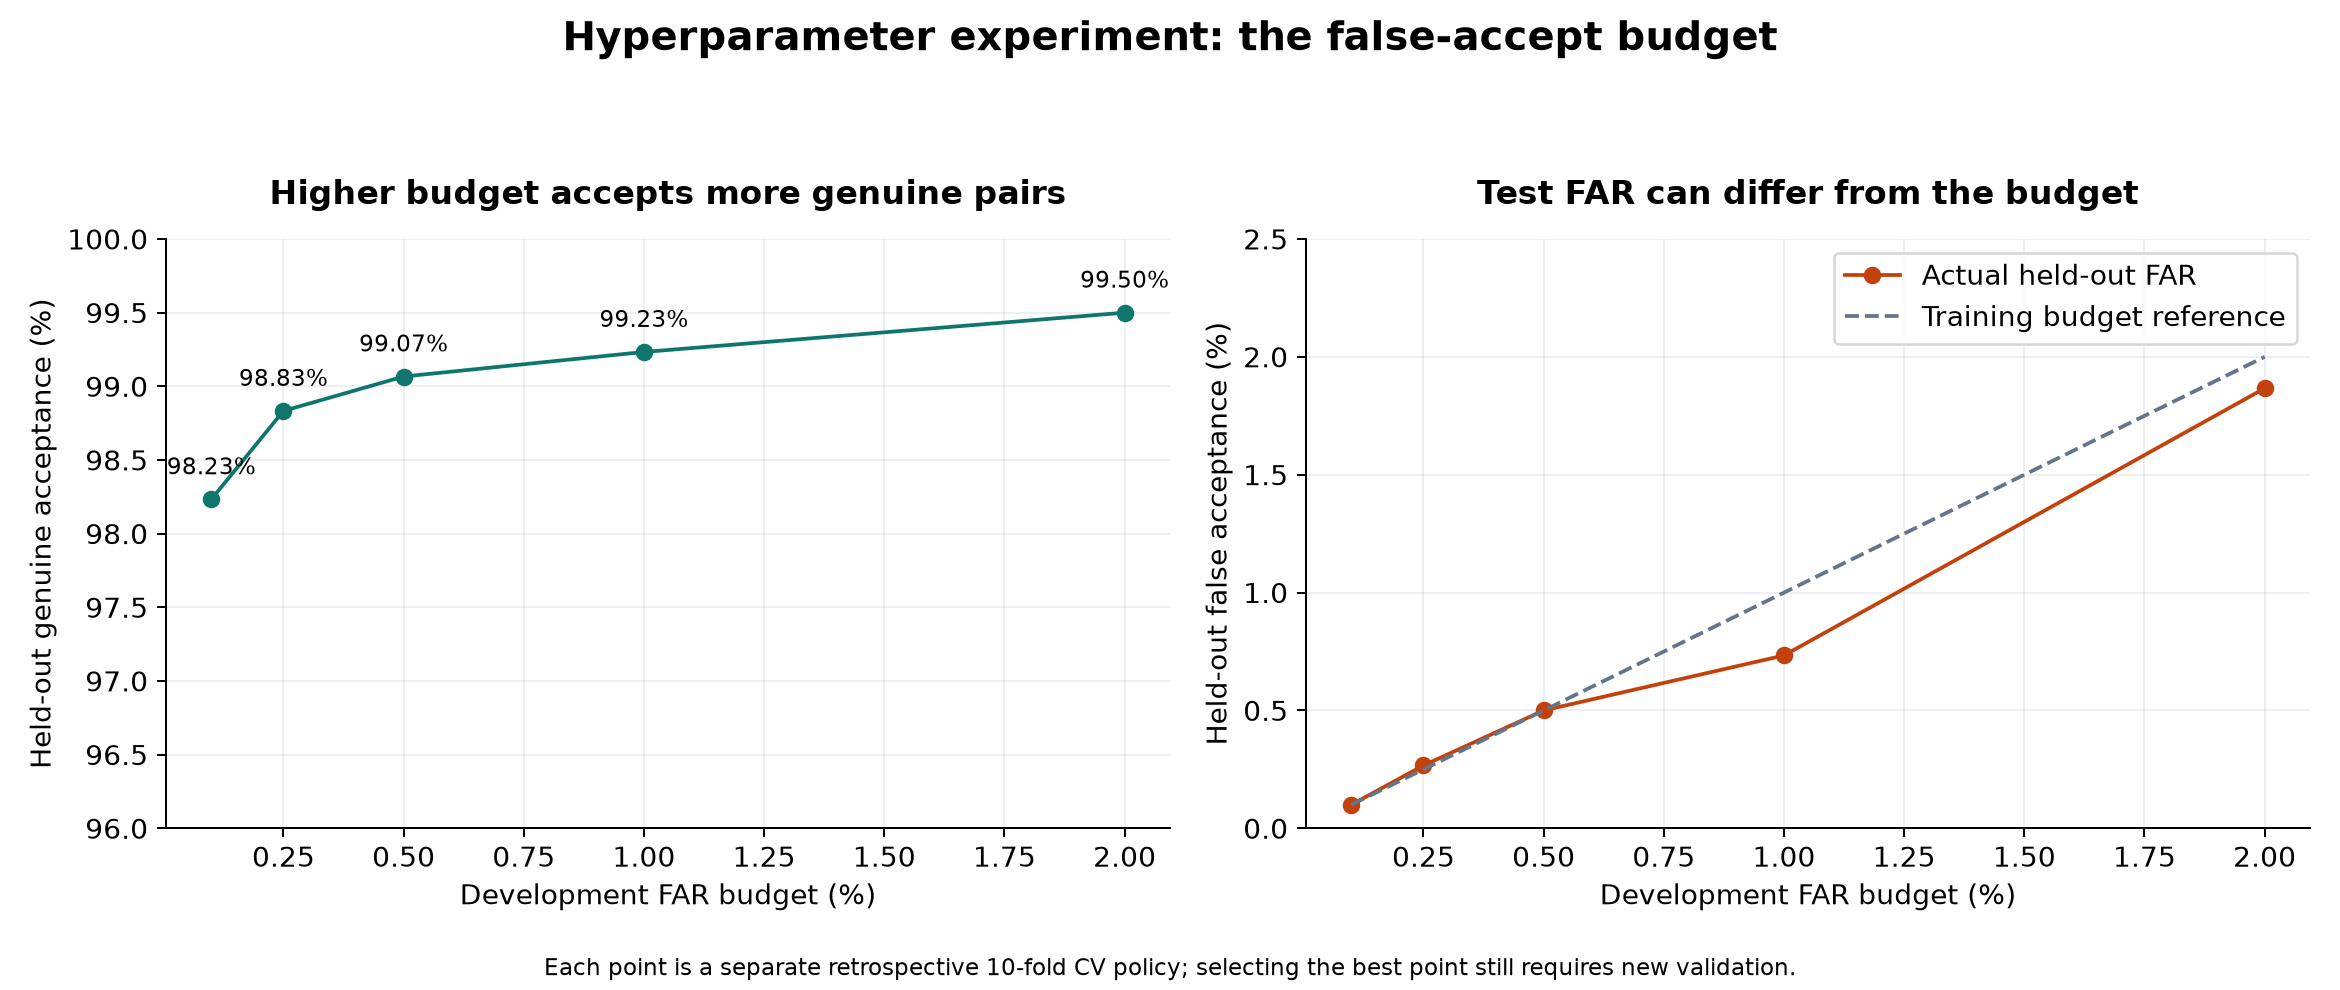

In [7]:
display(Image(filename=str(ROOT / 'reports/lfw_visualizations/02_far_budget_tradeoff.png')))


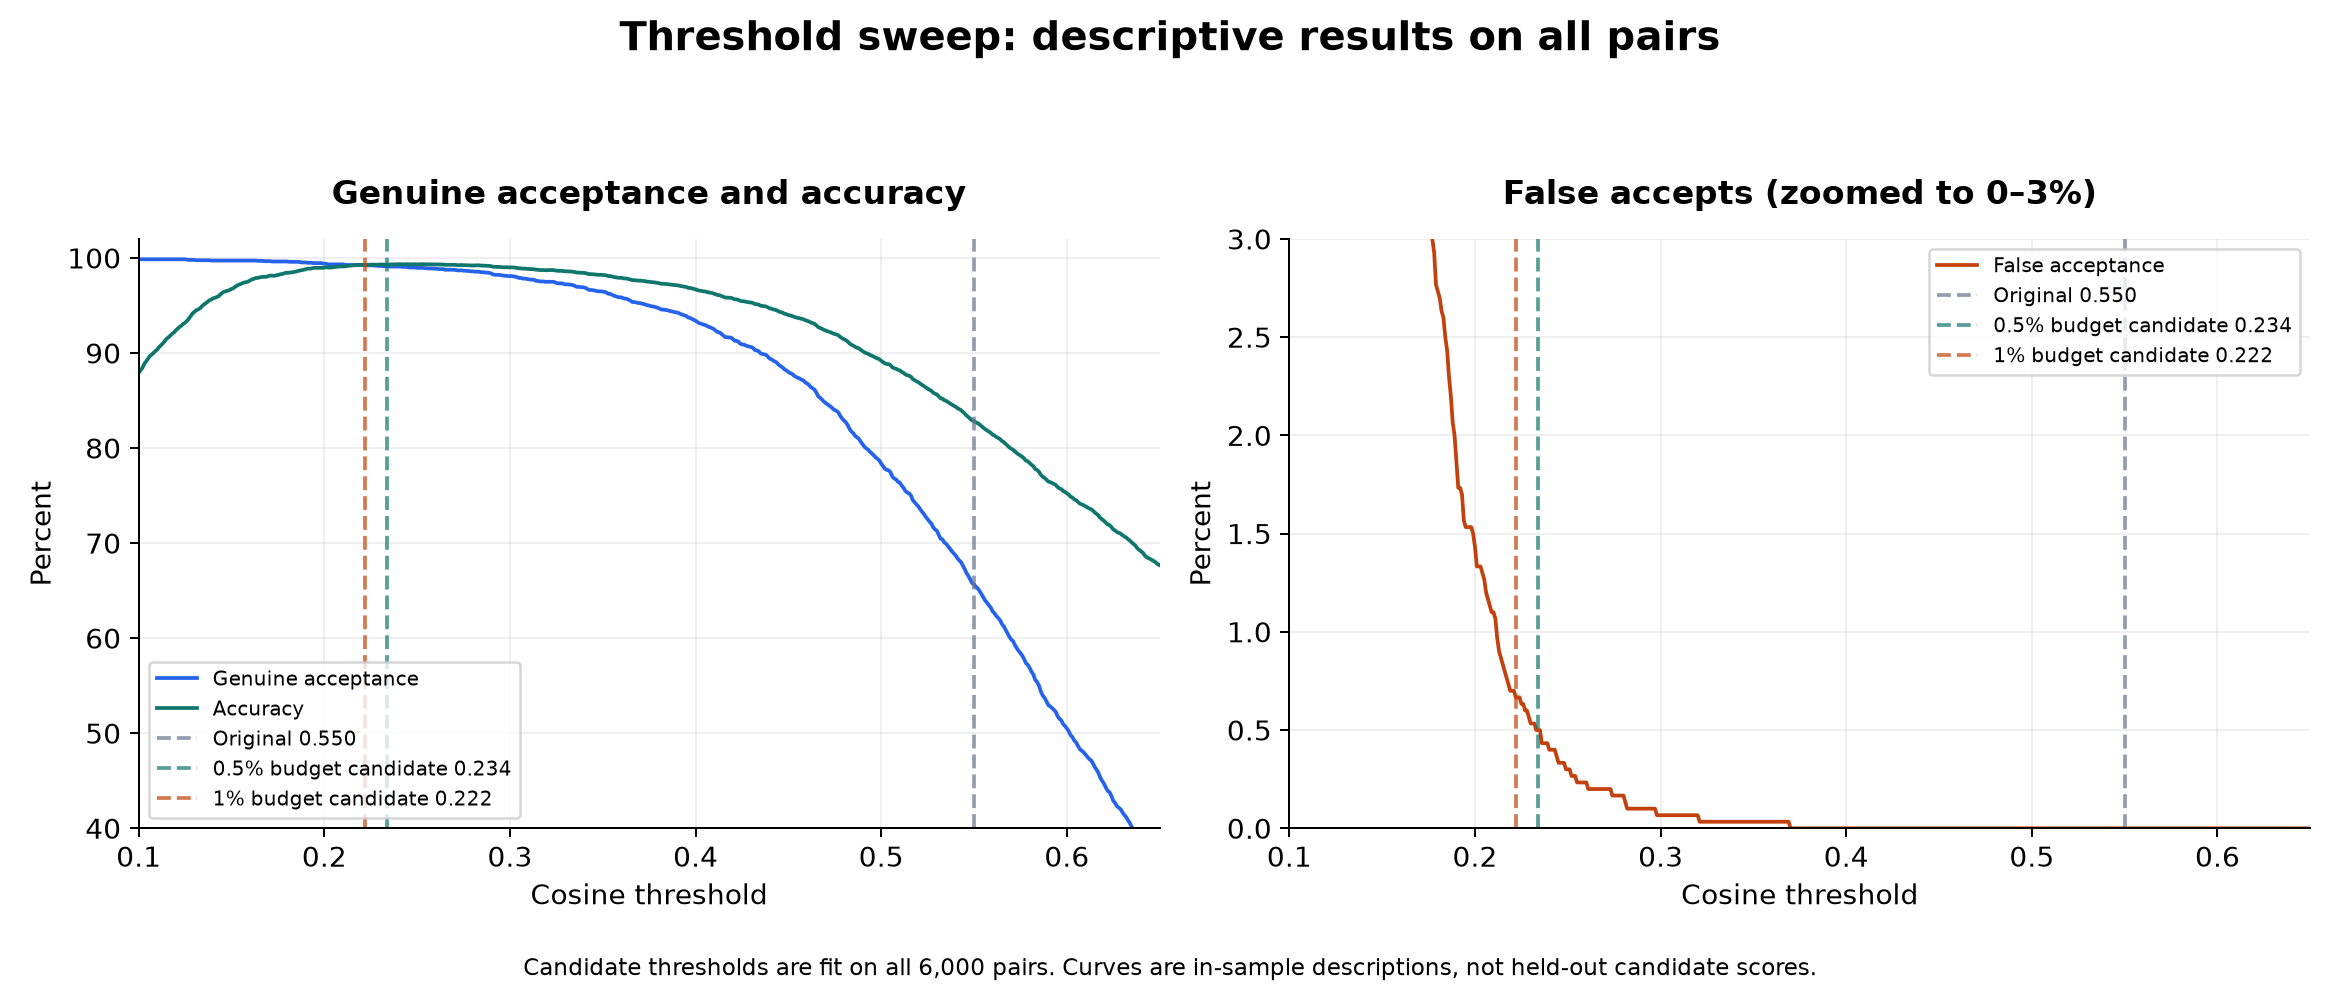

In [8]:
display(Image(filename=str(ROOT / 'reports/lfw_visualizations/03_threshold_sweep.png')))


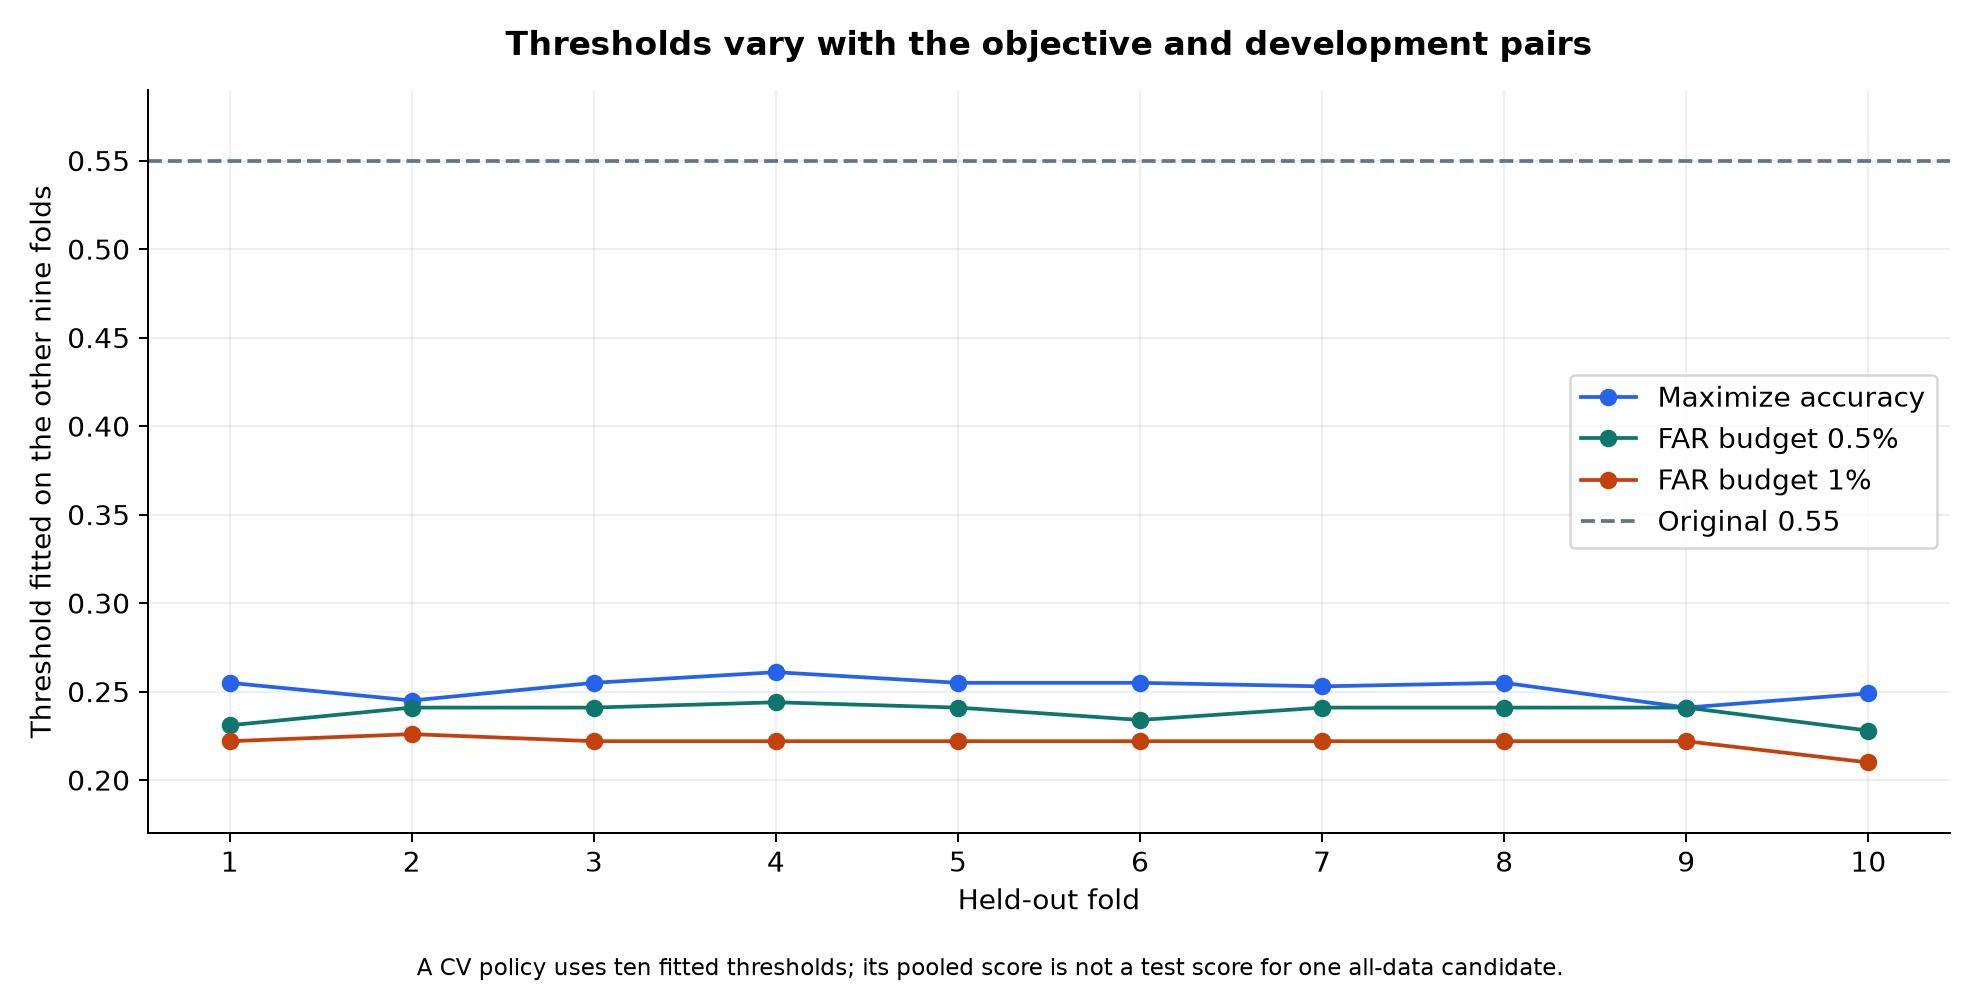

In [9]:
display(Image(filename=str(ROOT / 'reports/lfw_visualizations/04_fold_thresholds.png')))
